In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

df = pd.read_csv("/kaggle/input/datasets/sakinofbd/bangladesh-aqi-dataset-20002025/AQI Bangladesh.csv")

df.head()

,city_id,city_name,lat,lon,datetime,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,aqi
0,7701354,Azimpur,23.7298,90.3854,2022-08-05T00:00,25.0,16.7,252.0,NaN,18.6,5.2,13.0,50.0
1,7701354,Azimpur,23.7298,90.3854,2022-08-05T01:00,18.5,12.3,249.0,NaN,18.5,5.7,19.0,50.0
2,7701354,Azimpur,23.7298,90.3854,2022-08-05T02:00,16.1,10.9,244.0,NaN,18.4,6.5,27.0,51.0
3,7701354,Azimpur,23.7298,90.3854,2022-08-05T03:00,15.4,10.3,233.0,NaN,17.2,6.9,39.0,51.0
4,7701354,Azimpur,23.7298,90.3854,2022-08-05T04:00,16.8,11.3,217.0,NaN,14.8,6.2,51.0,51.0


In [2]:
print(df.shape)
df.info()
df.describe()

(1048551, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048551 entries, 0 to 1048550
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   city_id           1048551 non-null  int64  
 1   city_name         1048551 non-null  object 
 2   lat               1048551 non-null  float64
 3   lon               1048551 non-null  float64
 4   datetime          1048551 non-null  object 
 5   pm10              1048551 non-null  float64
 6   pm2_5             1048551 non-null  float64
 7   carbon_monoxide   1048551 non-null  float64
 8   carbon_dioxide    274224 non-null   float64
 9   nitrogen_dioxide  1048551 non-null  float64
 10  sulphur_dioxide   1048551 non-null  float64
 11  ozone             1048551 non-null  float64
 12  aqi               1047855 non-null  float64
dtypes: float64(10), int64(1), object(2)
memory usage: 104.0+ MB


,city_id,lat,lon,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,aqi
count,1.048551e+06,1.048551e+06,1.048551e+06,1.048551e+06,1.048551e+06,1.048551e+06,274224.000000,1.048551e+06,1.048551e+06,1.048551e+06,1.047855e+06
mean,1.724447e+06,2.368415e+01,9.048250e+01,7.497350e+01,5.067619e+01,3.235187e+02,456.900698,1.678140e+01,9.784067e+00,7.378080e+01,1.150751e+02
std,1.702309e+06,9.928910e-01,8.652851e-01,6.744548e+01,4.186072e+01,2.804124e+02,20.958356,1.734989e+01,9.302039e+00,4.104232e+01,5.262795e+01
min,1.185100e+06,2.143973e+01,8.863779e+01,2.000000e-01,1.000000e-01,1.000000e-01,408.000000,-1.000000e-01,0.000000e+00,-3.000000e+00,9.000000e+00
25%,1.185241e+06,2.301440e+01,9.006273e+01,2.630000e+01,1.900000e+01,1.550000e+02,444.000000,4.400000e+00,2.900000e+00,4.500000e+01,6.800000e+01
50%,1.185263e+06,2.371040e+01,9.040744e+01,5.610000e+01,3.990000e+01,2.720000e+02,452.000000,1.070000e+01,6.600000e+00,6.400000e+01,1.170000e+02
75%,1.209562e+06,2.407821e+01,9.097640e+01,9.990000e+01,6.960000e+01,4.510000e+02,464.000000,2.440000e+01,1.420000e+01,9.400000e+01,1.572355e+02
max,7.921384e+06,2.567419e+01,9.221946e+01,7.879000e+02,5.513000e+02,5.084000e+03,740.000000,1.780000e+02,1.724000e+02,3.280000e+02,2.995996e+02


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048551 entries, 0 to 1048550
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   city_id           1048551 non-null  int64  
 1   city_name         1048551 non-null  object 
 2   lat               1048551 non-null  float64
 3   lon               1048551 non-null  float64
 4   datetime          1048551 non-null  object 
 5   pm10              1048551 non-null  float64
 6   pm2_5             1048551 non-null  float64
 7   carbon_monoxide   1048551 non-null  float64
 8   carbon_dioxide    274224 non-null   float64
 9   nitrogen_dioxide  1048551 non-null  float64
 10  sulphur_dioxide   1048551 non-null  float64
 11  ozone             1048551 non-null  float64
 12  aqi               1047855 non-null  float64
dtypes: float64(10), int64(1), object(2)
memory usage: 104.0+ MB


city_id                  0
city_name                0
lat                      0
lon                      0
datetime                 0
pm10                     0
pm2_5                    0
carbon_monoxide          0
carbon_dioxide      774327
nitrogen_dioxide         0
sulphur_dioxide          0
ozone                    0
aqi                    696
dtype: int64

In [4]:
df = df.drop(columns=["city_id", "city_name","lat","lon","datetime","carbon_monoxide","nitrogen_dioxide","sulphur_dioxide","ozone"])
df = df.drop(columns=["carbon_dioxide"])
df = df.drop_duplicates()
df = df.dropna()

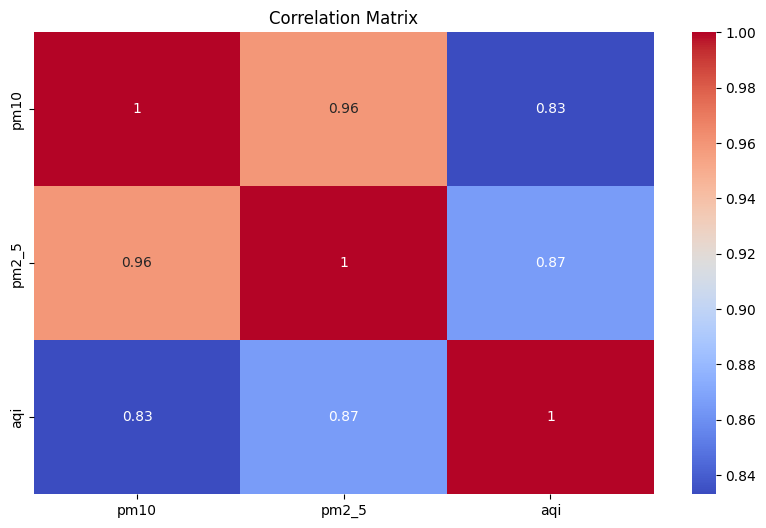

In [5]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [6]:
df.head()

,pm10,pm2_5,aqi
0,25.0,16.7,50.0
1,18.5,12.3,50.0
2,16.1,10.9,51.0
3,15.4,10.3,51.0
4,16.8,11.3,51.0


In [7]:
X = df.drop("aqi", axis=1)
y = df["aqi"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [9]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(max_depth=15, n_estimators=200, n_jobs=-1,
                      random_state=42)

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))
mse=mean_squared_error(y_test, y_pred)
rmse=mse**0.5
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 13.248888461214316
R2: 0.8546904285865459
MSE: 383.3651593632681
RMSE: 19.579712954057015


In [11]:
import pandas as pd

importance = pd.Series(model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False))

pm2_5    0.965091
pm10     0.034909
dtype: float64


In [12]:
new_data=[[25,16.7],[18.5,12.3]]
prediction=model.predict(new_data)
print(prediction)

[63.91208909 53.82926589]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


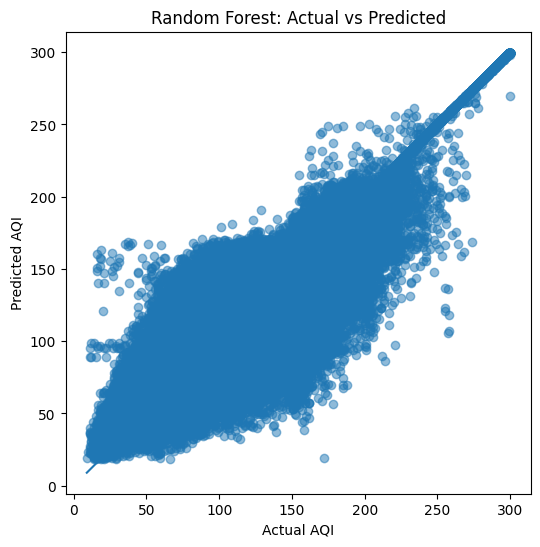

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred, alpha=0.5)

# perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()])

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Random Forest: Actual vs Predicted")
plt.show()